In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile

zip_path = "/content/drive/MyDrive/s1s2_landslide_reference_data.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/dataset")

In [ ]:
train_path = "/content/dataset/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"
val_path   = "/content/dataset/s1s2_landslide_reference_data/reference_data/val_n3_s1s2.h5"
test_path  = "/content/dataset/s1s2_landslide_reference_data/reference_data/testspt_n3_s1s2.h5"

In [ ]:
import h5py
import numpy as np

# Choose one of the paths to inspect, e.g., the training file
file_to_inspect = "/content/dataset/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5"

print(f"File Name: {file_to_inspect}")

with h5py.File(file_to_inspect, 'r') as f:
    # Get all keys in the HDF5 file, which correspond to different data types/bands
    all_keys = list(f.keys())

    # Filter out the mask key to get only the feature bands
    feature_keys = [k for k in all_keys if k != "None_MASK"]

    # Number of Bands
    num_bands = len(feature_keys)
    print(f"\nNumber of Bands: {num_bands}")

    # Band Descriptions
    print("\nBand Descriptions:")
    for i, key in enumerate(feature_keys):
        print(f"  Band {i+1}: {key}")

    # BAND 1, 2, and 3 information
    print("\nBand 1, 2, and 3 Information:")
    for i in range(min(3, num_bands)):
        band_name = feature_keys[i]
        band_data = f[band_name][:] # Load data for the band
        print(f"  Band {i+1} ({band_name}):")
        print(f"    Shape: {band_data.shape}")
        print(f"    Data Type: {band_data.dtype}")
        print(f"    Min Value: {np.min(band_data):.4f}")
        print(f"    Max Value: {np.max(band_data):.4f}")
        print(f"    Mean Value: {np.mean(band_data):.4f}")

File Name: /content/dataset/s1s2_landslide_reference_data/reference_data/train_n3_s1s2.h5

Number of Bands: 59

Band Descriptions:
  Band 1: None_DEM
  Band 2: None_SLOPE
  Band 3: POST1_ALPHA
  Band 4: POST1_ANISOTROPY
  Band 5: POST1_B02
  Band 6: POST1_B03
  Band 7: POST1_B04
  Band 8: POST1_B05
  Band 9: POST1_B06
  Band 10: POST1_B07
  Band 11: POST1_B08
  Band 12: POST1_B11
  Band 13: POST1_B12
  Band 14: POST1_B8A
  Band 15: POST1_COHVV
  Band 16: POST1_ENTROPY
  Band 17: POST1_NDVI
  Band 18: POST1_gVH
  Band 19: POST1_gVV
  Band 20: POST2_ALPHA
  Band 21: POST2_ANISOTROPY
  Band 22: POST2_COHVV
  Band 23: POST2_ENTROPY
  Band 24: POST2_gVH
  Band 25: POST2_gVV
  Band 26: POST3_ALPHA
  Band 27: POST3_ANISOTROPY
  Band 28: POST3_COHVV
  Band 29: POST3_ENTROPY
  Band 30: POST3_gVH
  Band 31: POST3_gVV
  Band 32: PRE1_ALPHA
  Band 33: PRE1_ANISOTROPY
  Band 34: PRE1_B02
  Band 35: PRE1_B03
  Band 36: PRE1_B04
  Band 37: PRE1_B05
  Band 38: PRE1_B06
  Band 39: PRE1_B07
  Band 40: P

In [ ]:
pip install wandb weave

INFO: pip is looking at multiple versions of opentelemetry-sdk to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 27.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.9/45.9 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 7.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.9/170.9 kB 13.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 203.7/203.7 kB 17.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 61.3/61.3 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 71.8/71.8 kB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 69.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.5/58.5 kB 5.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.9/214.9 kB 16.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 100.

In [ ]:
import os
os.environ['WANDB_API_KEY'] = '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'

In [ ]:
dice_history = {}

In [ ]:
import torch
import torch.nn.functional as F
from torchvision.models.detection import roi_heads

def dice_bce_mask_loss(
    mask_logits,
    proposals,
    gt_masks,
    gt_labels,
    mask_matched_idxs
):

    discretization_size = mask_logits.shape[-1]

    labels = [
        gt_label[idxs]
        for gt_label, idxs in zip(
            gt_labels,
            mask_matched_idxs
        )
    ]

    mask_targets = [
        roi_heads.project_masks_on_boxes(
            masks,
            proposals_per_image,
            matched_idxs,
            discretization_size
        )
        for masks, proposals_per_image, matched_idxs in zip(
            gt_masks,
            proposals,
            mask_matched_idxs
        )
    ]

    labels = torch.cat(labels, dim=0)
    mask_targets = torch.cat(mask_targets, dim=0)

    if mask_targets.numel() == 0:
        return mask_logits.sum() * 0

    mask_logits = mask_logits[
        torch.arange(labels.shape[0], device=labels.device),
        labels
    ]

    # BCE component
    bce_loss = F.binary_cross_entropy_with_logits(
        mask_logits,
        mask_targets
    )

    # Dice component
    probs = torch.sigmoid(mask_logits)

    probs = probs.flatten(1)
    targets = mask_targets.flatten(1)

    intersection = (probs * targets).sum(1)

    smooth = 1e-6

    dice = (
        2 * intersection + smooth
    ) / (
        probs.sum(1) +
        targets.sum(1) +
        smooth
    )

    dice_loss = 1 - dice.mean()

    dice_history["dice_loss"] = dice_loss.item()
    dice_history["bce_loss"] = bce_loss.item()

    total_loss = bce_loss + dice_loss

    return total_loss

In [ ]:
from torchvision.models.detection import roi_heads

roi_heads.maskrcnn_loss = dice_bce_mask_loss

In [ ]:
print(
    roi_heads.maskrcnn_loss is dice_bce_mask_loss
)

True


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import numpy as np
import h5py
import wandb
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader

from torchvision.models.detection import MaskRCNN
from torchvision.models.detection.backbone_utils import resnet_fpn_backbone
from torchvision.models.detection import roi_heads


In [ ]:
from torchvision.models.detection import roi_heads

print(
    roi_heads.maskrcnn_loss.__name__
)

dice_bce_mask_loss


In [ ]:
import torch
import h5py
import numpy as np

class LandslideDataset(torch.utils.data.Dataset):

    def __init__(self, h5_path):

        self.h5_path = h5_path

        with h5py.File(h5_path, "r") as f:

            self.masks = f["None_MASK"][:]

            self.feature_keys = [
                k for k in f.keys()
                if k != "None_MASK"
            ]

            self.features = np.concatenate(
                [f[k][:] for k in self.feature_keys],
                axis=1
            )

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):

        image = self.features[idx]
        image = torch.tensor(
            image,
            dtype=torch.float32
        )

        mask = self.masks[idx, 0]

        mask = (
            torch.tensor(mask)
            .float()
        )

        pos = torch.where(mask > 0)

        if len(pos[0]) == 0:

            boxes = torch.tensor(
                [[0, 0, 1, 1]],
                dtype=torch.float32
            )

            labels = torch.tensor(
                [0],
                dtype=torch.int64
            )

        else:

            xmin = pos[1].min()
            xmax = pos[1].max()

            ymin = pos[0].min()
            ymax = pos[0].max()

            boxes = torch.tensor(
                [[xmin, ymin, xmax, ymax]],
                dtype=torch.float32
            )

            labels = torch.tensor(
                [1],
                dtype=torch.int64
            )

        target = {}

        target["boxes"] = boxes

        target["labels"] = labels

        target["masks"] = mask.unsqueeze(0)

        return image, target

In [ ]:
train_ds = LandslideDataset(train_path)

img, target = train_ds[0]

print(type(img))
print(img.shape)

print(target.keys())

print(target["boxes"].shape)
print(target["masks"].shape)

<class 'torch.Tensor'>
torch.Size([59, 128, 128])
dict_keys(['boxes', 'labels', 'masks'])
torch.Size([1, 4])
torch.Size([1, 128, 128])


In [ ]:
train_ds = LandslideDataset(train_path)
val_ds   = LandslideDataset(val_path)
test_ds  = LandslideDataset(test_path)

print(len(train_ds))
print(len(val_ds))
print(len(test_ds))

355
88
76


In [ ]:
def collate_fn(batch):
    return tuple(zip(*batch))

train_loader = DataLoader(
    train_ds,
    batch_size=4,
    shuffle=True,
    collate_fn=collate_fn
)

val_loader = DataLoader(
    val_ds,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)

test_loader = DataLoader(
    test_ds,
    batch_size=4,
    shuffle=False,
    collate_fn=collate_fn
)

In [ ]:
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [ ]:
backbone = resnet_fpn_backbone(
    "resnet50",
    weights=None
)

backbone.body.conv1 = nn.Conv2d(
    59,
    64,
    kernel_size=7,
    stride=2,
    padding=3,
    bias=False
)

model = MaskRCNN(
    backbone=backbone,
    num_classes=2,
    image_mean=[0.0]*59,
    image_std=[1.0]*59
)

model.to(device)

/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:135: UserWarning: Using 'backbone_name' as positional parameter(s) is deprecated since 0.13 and may be removed in the future. Please use keyword parameter(s) instead.
  warnings.warn(


MaskRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0], std=[1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0, 1.0])
      Resize(min_size=(800,), max_size=1333, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (conv1): Conv2d(59, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (bn1): FrozenBatchNorm2d(64, eps=1e-05)
      (relu): ReLU(inplace=True)
      (maxpool): MaxPool

In [ ]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=1e-4
)

In [ ]:
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode='min',
    factor=0.5,
    patience=3
)

In [ ]:
from torchvision.models.detection import roi_heads

print(
    roi_heads.maskrcnn_loss.__name__
)

dice_bce_mask_loss


In [ ]:
wandb.init(
    project="landslide-maskrcnn",
    name="resnet50fpn-dice-loss-indpendent",
    config={
        "epochs": 50,
        "batch_size": 4,
        "lr": 1e-4,
        "loss": "BCE + Dice"
    }
)

/usr/local/lib/python3.12/dist-packages/notebook/notebookapp.py:191: SyntaxWarning: invalid escape sequence '\/'
  | |_| | '_ \/ _` / _` |  _/ -_)
wandb: [wandb.login()] Loaded credentials for https://api.wandb.ai from WANDB_API_KEY.
wandb: Currently logged in as: kashishaggcha (kashishaggcha-thapar-university) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


In [ ]:
from torchvision.models.detection import roi_heads

print(
    "Current loss:",
    roi_heads.maskrcnn_loss.__name__
)

Current loss: dice_bce_mask_loss


In [ ]:
import time
import torch
import numpy as np

def evaluate_segmentation_metrics(
    model,
    dataloader,
    device
):

    model.eval()

    dice_scores = []
    iou_scores = []

    TP = 0
    FP = 0
    FN = 0
    TN = 0

    with torch.no_grad():

        for images, targets in dataloader:

            images = [
                img.to(device)
                for img in images
            ]

            outputs = model(images)

            for output, target in zip(
                outputs,
                targets
            ):

              if len(output["masks"]) == 0:
                  pred_mask = torch.zeros_like(
                      target["masks"].any(dim=0)
                  )

              else:
                pred_mask = (
                    output["masks"][:, 0] > 0.5
                ).any(dim=0)

                gt_mask = (
                    target["masks"] > 0
                ).any(dim=0)

                pred_mask = pred_mask.cpu()
                gt_mask = gt_mask.cpu()

                intersection = (
                    pred_mask & gt_mask
                ).sum().item()

                union = (
                    pred_mask | gt_mask
                ).sum().item()

                pred_sum = pred_mask.sum().item()
                gt_sum = gt_mask.sum().item()

                dice = (
                    2 * intersection + 1e-6
                ) / (
                    pred_sum + gt_sum + 1e-6
                )

                iou = (
                    intersection + 1e-6
                ) / (
                    union + 1e-6
                )

                dice_scores.append(dice)
                iou_scores.append(iou)

                TP += (
                    pred_mask & gt_mask
                ).sum().item()

                FP += (
                    pred_mask & ~gt_mask
                ).sum().item()

                FN += (
                    ~pred_mask & gt_mask
                ).sum().item()

                TN += (
                    ~pred_mask & ~gt_mask
                ).sum().item()


    correct_pixels = TP + TN
    total_pixels = TP + TN + FP + FN

    precision = TP / (TP + FP + 1e-6)

    recall = TP / (TP + FN + 1e-6)

    f1 = (
        2 * precision * recall
    ) / (
        precision + recall + 1e-6
    )

    accuracy = (
    TP + TN
    ) / (
    TP + TN + FP + FN + 1e-6
    )

    confusion_matrix = np.array([
        [TN, FP],
        [FN, TP]
    ])

    return {
        "dice": np.mean(dice_scores) if dice_scores else 0,
        "iou": np.mean(iou_scores) if iou_scores else 0,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy,
        "confusion_matrix": confusion_matrix
    }

start_time = time.time()
num_epochs = 50

train_losses = []
val_losses = []

train_accs = []
val_accs = []

for epoch in range(num_epochs):

    # ====================
    # TRAIN
    # ====================

    model.train()

    train_loss = 0
    train_dice = 0
    train_bce = 0

    for images, targets in train_loader:

        images = [img.to(device) for img in images]

        targets = [
            {k: v.to(device) for k, v in t.items()}
            for t in targets
        ]

        loss_dict = model(images, targets)

        loss = sum(loss_dict.values())

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

        train_loss += loss.item()

        train_dice += dice_history.get(
            "dice_loss", 0
        )

        train_bce += dice_history.get(
            "bce_loss", 0
        )

    train_loss /= len(train_loader)

    train_dice /= len(train_loader)

    train_bce /= len(train_loader)

    # ====================
    # VALIDATION
    # ====================

    # Model is already in eval() mode for metric calculation below,
    # but we need to temporarily set it to train() to get loss_dict
    # without computing gradients.
    val_loss = 0

    with torch.no_grad():

        for images, targets in val_loader:

            images = [
                img.to(device)
                for img in images
            ]

            targets = [
                {
                    k: v.to(device)
                    for k, v in t.items()
                }
                for t in targets
            ]

            # Temporarily set to train mode to get loss dict, then revert
            model.train()
            loss_dict = model(
                images,
                targets
            )
            model.eval()

            loss = sum(
                loss_dict.values()
            )

            val_loss += loss.item()

    val_loss /= len(val_loader)
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Calculate and store epoch accuracies for plotting if desired
    # This is a potentially expensive operation, consider doing it less frequently
    epoch_train_metrics = evaluate_segmentation_metrics(
        model,
        train_loader,
        device
    )

    epoch_val_metrics = evaluate_segmentation_metrics(
        model,
        val_loader,
        device
    )

    train_acc = epoch_train_metrics["accuracy"]
    val_acc = epoch_val_metrics["accuracy"]

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    scheduler.step(val_loss)

    wandb.log({
    "epoch": epoch + 1,
    "train_loss": train_loss,
    "val_loss": val_loss,
    "train_accuracy": train_acc,
    "val_accuracy": val_acc,
    "dice_loss": train_dice,
    "bce_loss": train_bce,
    "learning_rate":
        optimizer.param_groups[0]["lr"]
})

    print(
    f"Epoch {epoch+1}/{num_epochs} | "
    f"Train Loss={train_loss:.4f} | "
    f"Val Loss={val_loss:.4f} | "
    f"Train Acc={train_acc:.4f} | "
    f"Val Acc={val_acc:.4f}"
)

# Calculate final metrics after training loop for logging and printing
final_train_metrics = evaluate_segmentation_metrics(
    model,
    train_loader,
    device
)
final_val_metrics = evaluate_segmentation_metrics(
    model,
    val_loader,
    device
)
final_test_metrics = evaluate_segmentation_metrics(
    model,
    test_loader,
    device
)
end_time = time.time()

training_time = end_time - start_time

print(
    f"\nTotal Training Time: {training_time:.2f} sec"
)

print(
    f"Total Training Time: {training_time/60:.2f} min"
)

Epoch 1/50 | Train Loss=73.5496 | Val Loss=62.9434 | Train Acc=0.7495 | Val Acc=0.7266
Epoch 2/50 | Train Loss=38.5776 | Val Loss=43.0065 | Train Acc=0.8308 | Val Acc=0.8188
Epoch 3/50 | Train Loss=27.8852 | Val Loss=36.1627 | Train Acc=0.8634 | Val Acc=0.8428
Epoch 4/50 | Train Loss=21.8474 | Val Loss=25.0955 | Train Acc=0.8481 | Val Acc=0.8151
Epoch 5/50 | Train Loss=16.5943 | Val Loss=20.3205 | Train Acc=0.7756 | Val Acc=0.7625
Epoch 6/50 | Train Loss=14.2143 | Val Loss=18.7328 | Train Acc=0.7002 | Val Acc=0.6710
Epoch 7/50 | Train Loss=13.0011 | Val Loss=15.2841 | Train Acc=0.7965 | Val Acc=0.7733
Epoch 8/50 | Train Loss=10.6215 | Val Loss=13.7022 | Train Acc=0.7340 | Val Acc=0.7094
Epoch 9/50 | Train Loss=8.9981 | Val Loss=12.3679 | Train Acc=0.7858 | Val Acc=0.7609
Epoch 10/50 | Train Loss=8.1538 | Val Loss=11.2526 | Train Acc=0.6173 | Val Acc=0.6017
Epoch 11/50 | Train Loss=7.5279 | Val Loss=9.8760 | Train Acc=0.8248 | Val Acc=0.8054
Epoch 12/50 | Train Loss=6.9529 | Val Loss=9.

In [ ]:
torch.save(
    model.state_dict(),
    "trained_maskrcnn.pth"
)

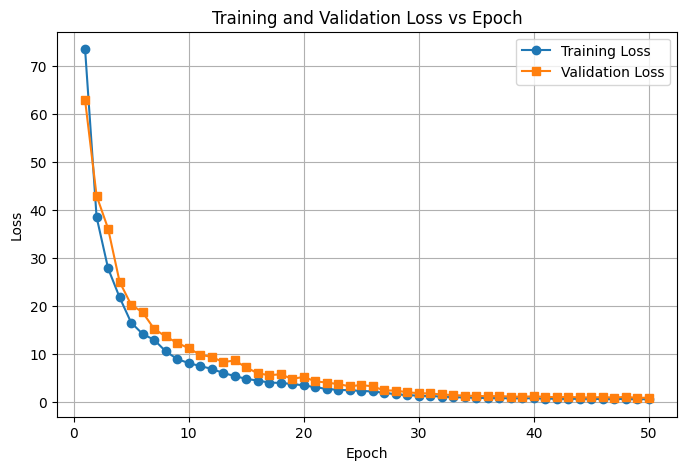

In [ ]:
import matplotlib.pyplot as plt

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs, train_losses, marker='o', label='Training Loss')
plt.plot(epochs, val_losses, marker='s', label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss vs Epoch')
plt.legend()
plt.grid(True)

plt.show()

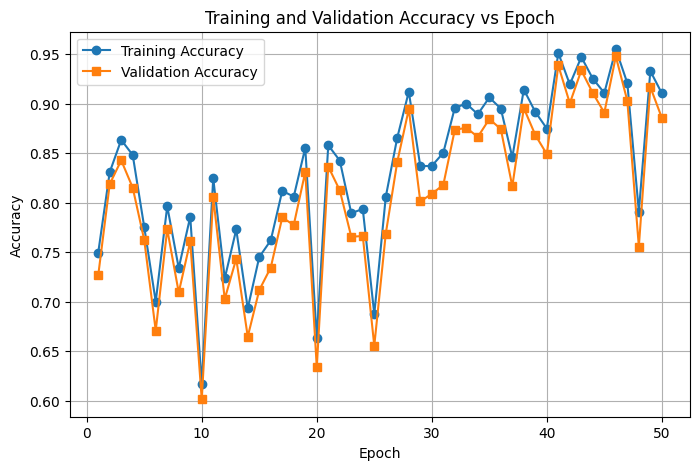

In [ ]:
epochs = range(1, len(train_accs) + 1)

plt.figure(figsize=(8,5))
plt.plot(epochs, train_accs, marker='o', label='Training Accuracy')
plt.plot(epochs, val_accs, marker='s', label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy vs Epoch')
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import torch
import numpy as np

def evaluate_segmentation_metrics(
    model,
    dataloader,
    device
):

    model.eval()

    dice_scores = []
    iou_scores = []

    TP = 0
    FP = 0
    FN = 0
    TN = 0

    with torch.no_grad():

        for images, targets in dataloader:

            images = [
                img.to(device)
                for img in images
            ]

            outputs = model(images)

            for output, target in zip(
                outputs,
                targets
            ):

              if len(output["masks"]) == 0:
                  pred_mask = torch.zeros_like(
                      target["masks"].any(dim=0)
                  )

              else:
                pred_mask = (
                    output["masks"][:, 0] > 0.5
                ).any(dim=0)

                gt_mask = (
                    target["masks"] > 0
                ).any(dim=0)

                pred_mask = pred_mask.cpu()
                gt_mask = gt_mask.cpu()

                intersection = (
                    pred_mask & gt_mask
                ).sum().item()

                union = (
                    pred_mask | gt_mask
                ).sum().item()

                pred_sum = pred_mask.sum().item()
                gt_sum = gt_mask.sum().item()

                dice = (
                    2 * intersection + 1e-6
                ) / (
                    pred_sum + gt_sum + 1e-6
                )

                iou = (
                    intersection + 1e-6
                ) / (
                    union + 1e-6
                )

                dice_scores.append(dice)
                iou_scores.append(iou)

                TP += (
                    pred_mask & gt_mask
                ).sum().item()

                FP += (
                    pred_mask & ~gt_mask
                ).sum().item()

                FN += (
                    ~pred_mask & gt_mask
                ).sum().item()

                TN += (
                    ~pred_mask & ~gt_mask
                ).sum().item()


    correct_pixels = TP + TN
    total_pixels = TP + TN + FP + FN

    precision = TP / (TP + FP + 1e-6)

    recall = TP / (TP + FN + 1e-6)

    f1 = (
        2 * precision * recall
    ) / (
        precision + recall + 1e-6
    )

    accuracy = (
    TP + TN
    ) / (
    TP + TN + FP + FN + 1e-6
    )

    confusion_matrix = np.array([
        [TN, FP],
        [FN, TP]
    ])

    return {
        "dice": np.mean(dice_scores) if dice_scores else 0,
        "iou": np.mean(iou_scores) if iou_scores else 0,
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "accuracy": accuracy,
        "confusion_matrix": confusion_matrix
    }

In [ ]:
print(
    f"Training Accuracy : {final_train_metrics['accuracy']:.4f}"
)

print(
    f"Training Dice: {final_train_metrics['dice']:.4f}"
)

print(
    f"Training IoU : {final_train_metrics['iou']:.4f}"
)

Training Accuracy : 0.9104
Training Dice: 0.6064
Training IoU : 0.4860


In [ ]:
print(
    f"Validation Accuracy : {final_val_metrics['accuracy']:.4f}"
)

print(
    f"Validation Dice: {final_val_metrics['dice']:.4f}"
)

print(
    f"Validation IoU : {final_val_metrics['iou']:.4f}"
)

Validation Accuracy : 0.8856
Validation Dice: 0.5337
Validation IoU : 0.4164


In [ ]:
final_test_metrics = evaluate_segmentation_metrics(
    model,
    test_loader,
    device
)

print(
    f"Test Accuracy  : {final_test_metrics['accuracy']:.4f}"
)

print(
    f"Test Dice      : {final_test_metrics['dice']:.4f}"
)

print(
    f"Test IoU       : {final_test_metrics['iou']:.4f}"
)

print(
    f"Test Precision : {final_test_metrics['precision']:.4f}"
)

print(
    f"Test Recall    : {final_test_metrics['recall']:.4f}"
)

print(
    f"Test F1 Score  : {final_test_metrics['f1']:.4f}"
)

Test Accuracy  : 0.8194
Test Dice      : 0.4459
Test IoU       : 0.3246
Test Precision : 0.3834
Test Recall    : 0.9623
Test F1 Score  : 0.5483


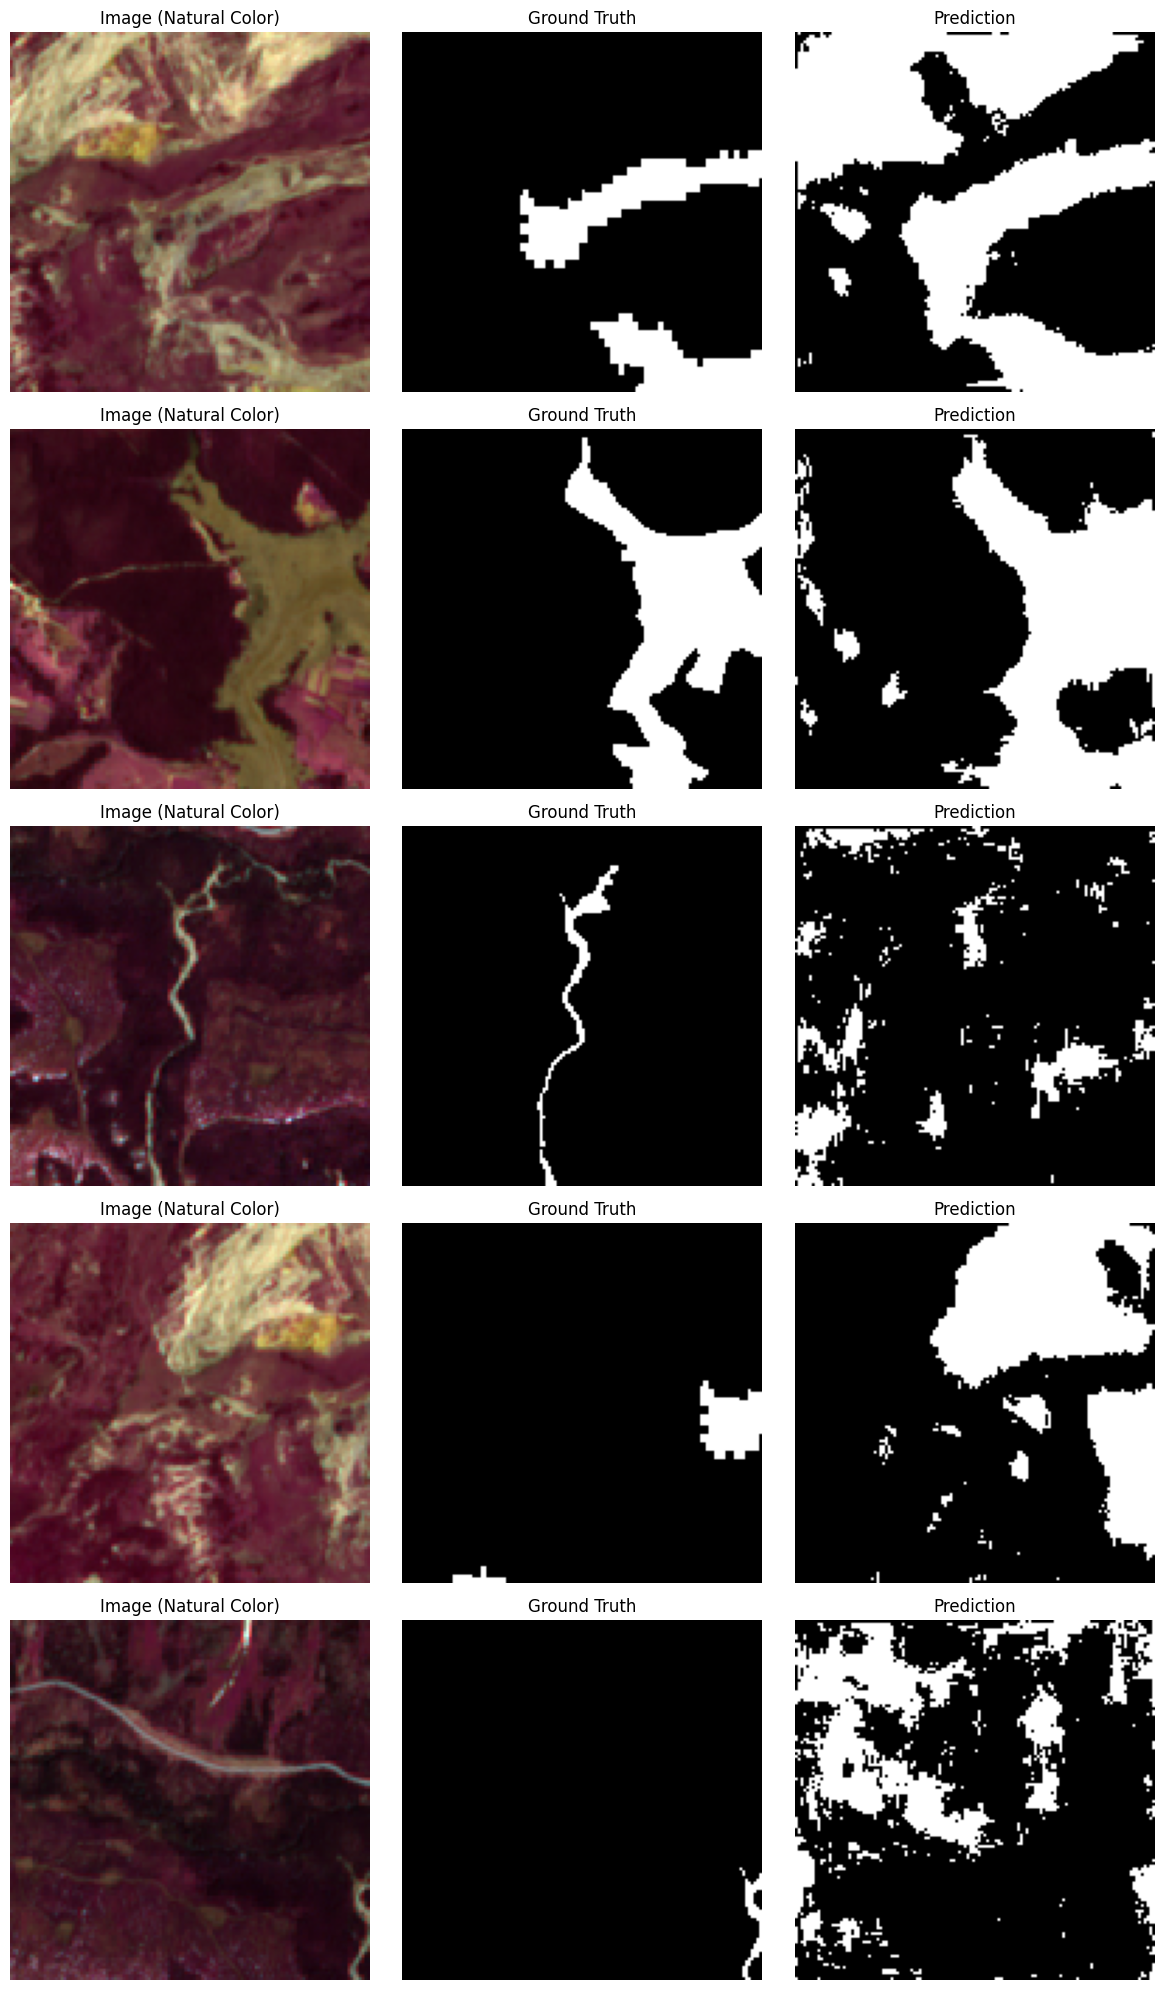

In [ ]:
import matplotlib.pyplot as plt
import random
import torch
import numpy as np # Ensure numpy is imported

model.eval()

num_samples = 5

indices = random.sample(
    range(len(test_ds)),
    num_samples
)

fig, axes = plt.subplots(
    num_samples,
    3,
    figsize=(12, 4 * num_samples)
)

with torch.no_grad():

    for i, idx in enumerate(indices):

        image, target = test_ds[idx]

        output = model(
            [image.to(device)]
        )[0]

        img = image.cpu().numpy()

        # Corrected indices based on HDF5 inspection:
        # POST1_B02 (Blue) = Index 5
        # POST1_B03 (Green) = Index 6
        # POST1_B04 (Red) = Index 7
        # POST1_B08 (NIR) = Index 11

        # Natural Color Composite (Red, Green, Blue) -> R, G, B
        rgb_channels = img[[7, 6, 5]] # Use POST1_B04, POST1_B03, POST1_B02

        rgb = rgb_channels.transpose(1, 2, 0)

        # Normalize for visualization
        rgb = (
            rgb - rgb.min()
        ) / (
            rgb.max() - rgb.min() + 1e-6
        )

        gt_mask = (
            target["masks"] > 0
        ).any(dim=0).cpu().numpy()

        if len(output["masks"]) > 0:
            pred_mask = (
                output["masks"][:, 0] > 0.5
            ).any(dim=0).cpu().numpy()
        else:
            pred_mask = np.zeros_like(
                gt_mask
            )

        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title("Image (Natural Color)") # Updated title
        axes[i, 0].axis("off")

        axes[i, 1].imshow(
            gt_mask,
            cmap="gray"
        )
        axes[i, 1].set_title("Ground Truth")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(
            pred_mask,
            cmap="gray"
        )
        axes[i, 2].set_title("Prediction")
        axes[i, 2].axis("off")

plt.tight_layout()
plt.show()

In [ ]:
print(
    final_test_metrics["confusion_matrix"]
)

[[883744 219573]
 [  5355 136512]]


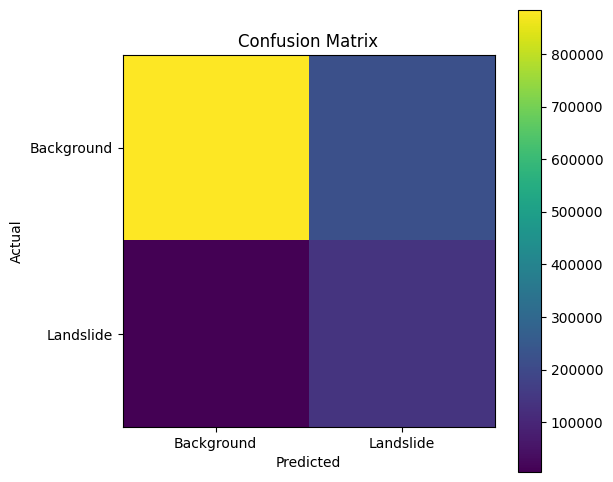

In [ ]:
import matplotlib.pyplot as plt

cm = final_test_metrics["confusion_matrix"]

plt.figure(figsize=(6,6))

plt.imshow(cm)

plt.colorbar()

plt.xticks([0,1],
           ["Background",
            "Landslide"])

plt.yticks([0,1],
           ["Background",
            "Landslide"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

plt.show()

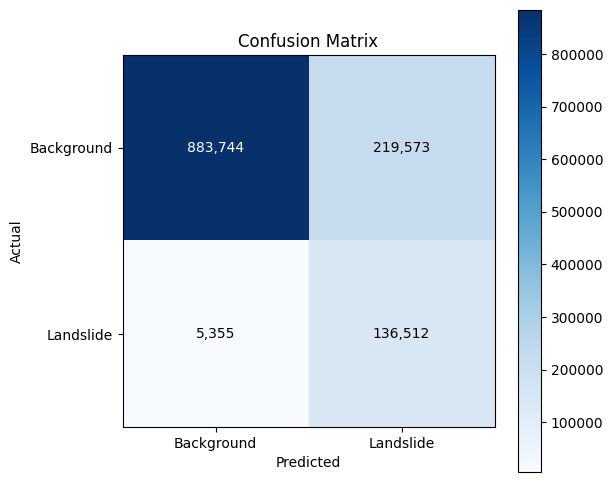

In [ ]:
import matplotlib.pyplot as plt

cm = final_test_metrics["confusion_matrix"]

plt.figure(figsize=(6,6))

plt.imshow(cm, cmap='Blues') # Added cmap for better visual distinction

plt.colorbar()

plt.xticks([0,1],
           ["Background",
            "Landslide"])

plt.yticks([0,1],
           ["Background",
            "Landslide"])

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Confusion Matrix")

# Add text annotations for numerical values
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            f"{cm[i,j]:,}", # Format with comma for thousands
            ha="center",
            va="center",
            color="black" if cm[i, j] < cm.max() / 2 else "white" # Adjust text color based on background for readability
        )

plt.show()

In [ ]:
wandb.log({

    # Training Metrics
    "train_accuracy":
        final_train_metrics["accuracy"],

    "train_dice":
        final_train_metrics["dice"],

    "train_iou":
        final_train_metrics["iou"],

    # Validation Metrics
    "val_accuracy":
        final_val_metrics["accuracy"],

    "val_dice":
        final_val_metrics["dice"],

    "val_iou":
        final_val_metrics["iou"],

    # Test Metrics
    "test_accuracy":
        final_test_metrics["accuracy"],

    "test_dice":
        final_test_metrics["dice"],

    "test_iou":
        final_test_metrics["iou"],

    "test_precision":
        final_test_metrics["precision"],

    "test_recall":
        final_test_metrics["recall"],

    "test_f1":
        final_test_metrics["f1"]
})

In [ ]:
import time

model.eval()

total_time = 0
num_images = 0

with torch.no_grad():

    for images, _ in test_loader:

        images = [
            img.to(device)
            for img in images
        ]

        start = time.time()

        outputs = model(images)

        end = time.time()

        total_time += (end - start)

        num_images += len(images)

avg_inference_time = (
    total_time / num_images
)

print(
    f"Average inference time/image: "
    f"{avg_inference_time:.4f} sec"
)

Average inference time/image: 0.1601 sec


In [ ]:
plt.savefig(
    "confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

<Figure size 640x480 with 0 Axes>

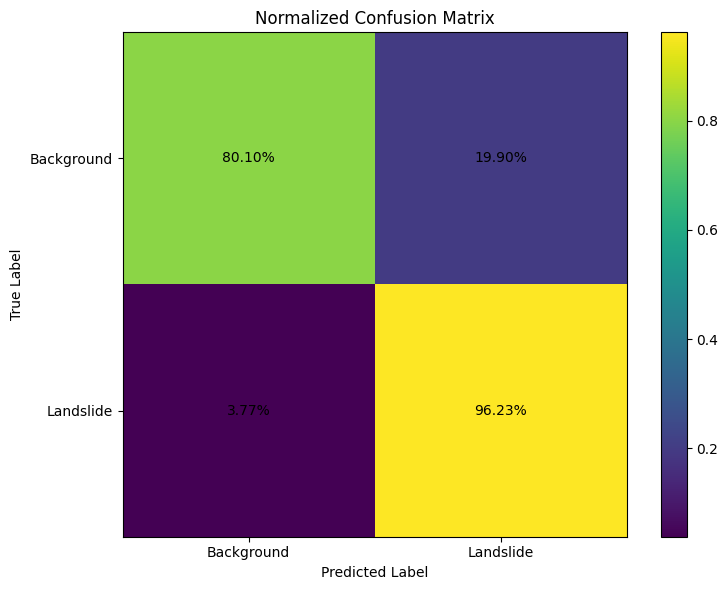

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Use the confusion matrix from the test_metrics dictionary
cm = final_test_metrics["confusion_matrix"]

cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

plt.figure(figsize=(8,6))

plt.imshow(cm_norm)

plt.colorbar()

plt.xticks(
    [0,1],
    ["Background", "Landslide"]
)

plt.yticks(
    [0,1],
    ["Background", "Landslide"]
)

for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j,
            i,
            f"{cm_norm[i,j]:.2%}",
            ha="center",
            va="center"
        )

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Normalized Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import random
import torch
import numpy as np

# Ensure model is in evaluation mode
model.eval()

num_samples = 5 # Number of samples to visualize

# Select random indices from the test dataset
indices = random.sample(
    range(len(test_ds)),
    num_samples
)

# Create a figure and a set of subplots for visualization
# 4 columns: Original Image, Ground Truth, Prediction, Red Overlay
fig, axes = plt.subplots(
    num_samples,
    4,
    figsize=(16, 4 * num_samples) # Adjusted width for 4 columns
)

# Handle cases where only one row or one column of plots exists
if num_samples == 1:
    axes = np.expand_dims(axes, axis=0) # Make it 2D if num_samples is 1

with torch.no_grad(): # Disable gradient calculations for inference

    for i, idx in enumerate(indices):

        # Get image and target from the test dataset
        image, target = test_ds[idx]

        # Move image to the appropriate device (CPU/GPU) and get model output
        output = model(
            [image.to(device)]
        )[0]

        # Convert image to numpy for matplotlib display
        img = image.cpu().numpy()

        # Define RGB channels based on the dataset structure
        # POST1_B02 (Blue) = Index 5
        # POST1_B03 (Green) = Index 6
        # POST1_B04 (Red) = Index 7
        rgb_channels = img[[7, 6, 5]] # Use POST1_B04, POST1_B03, POST1_B02

        # Transpose to (Height, Width, Channels) for matplotlib
        rgb = rgb_channels.transpose(1, 2, 0)

        # Normalize RGB image for visualization (0-1 range)
        rgb = (
            rgb - rgb.min()
        ) / (
            rgb.max() - rgb.min() + 1e-6
        )

        # Get ground truth mask
        gt_mask = (
            target["masks"] > 0
        ).any(dim=0).cpu().numpy()

        # Get predicted mask
        if len(output["masks"]) > 0:
            pred_mask = (
                output["masks"][:, 0] > 0.5 # Assuming class 1 is landslide, threshold 0.5
            ).any(dim=0).cpu().numpy()
        else:
            # If no masks are predicted, create an empty mask
            pred_mask = np.zeros_like(
                gt_mask
            )

        # Create the red overlay for the predicted landslide areas
        overlay_image = rgb.copy()
        red_color = np.array([1.0, 0.0, 0.0]) # Pure red (R, G, B)
        alpha = 0.5 # Transparency factor for the overlay

        # Blend original image with red where predicted mask is positive
        # This makes the landslide areas appear redder
        landslide_area = (pred_mask > 0)
        overlay_image[landslide_area] = (1 - alpha) * overlay_image[landslide_area] + alpha * red_color

        # Plotting
        axes[i, 0].imshow(rgb)
        axes[i, 0].set_title("Original Image (RGB)")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(
            gt_mask,
            cmap="gray" # Display masks in grayscale
        )
        axes[i, 1].set_title("Ground Truth Mask")
        axes[i, 1].axis("off")

        axes[i, 2].imshow(
            pred_mask,
            cmap="gray"
        )
        axes[i, 2].set_title("Predicted Mask")
        axes[i, 2].axis("off")

        axes[i, 3].imshow(overlay_image)
        axes[i, 3].set_title("Predicted Landslide Overlay")
        axes[i, 3].axis("off")

# Adjust layout to prevent overlap and display the plot
plt.tight_layout()
plt.show()

NameError: name 'model' is not defined